# A02 · Parte 1 — EDA del dataset Car Evaluation

**Autor:** Alejandro de la Peña

**Asignatura:** TPIA — Experto Universitario

## 1. Introducción y objetivos

El dataset *Car Evaluation* (UCI) contiene coches descritos por 6 atributos: precio de compra (`buying`), coste de
mantenimiento (`maint`), número de puertas (`doors`), número de personas (`persons`), tamaño del maletero (`lug_boot`) y
seguridad (`safety`). La variable objetivo es `class`, que indica si el coche es inaceptable (`unacc`), aceptable (`acc`),
bueno (`good`) o muy bueno (`vgood`).

El objetivo es entender los datos, comprobar su calidad y ver qué atributos influyen más en la clase.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")

## 2. Carga y comprensión de los datos

Los nombres de las columnas se toman de `car.names`. La última columna es la variable objetivo (`class`).

In [2]:
columnas = ["buying", "maint", "doors", "persons", "lug_boot", "safety", "class"]
df = pd.read_csv("datos/car/car.data", header=None, names=columnas)
df.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


In [3]:
df.shape

(1728, 7)

In [4]:
orden = {
    "buying" : ["low", "med", "high", "vhigh"],
    "maint" : ["low", "med", "high", "vhigh"],
    "doors" : ["2", "3", "4", "5more"],
    "persons" : ["2","4","more"],
    "lug_boot" : ["small", "med", "big"],
    "safety" : ["low", "med", "high"],
    "class" : ["unacc","acc","good","vgood"]
}

for col, categorias in orden.items():
    df[col] = pd.Categorical(df[col], categories=categorias, ordered=True)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   buying    1728 non-null   category
 1   maint     1728 non-null   category
 2   doors     1728 non-null   category
 3   persons   1728 non-null   category
 4   lug_boot  1728 non-null   category
 5   safety    1728 non-null   category
 6   class     1728 non-null   category
dtypes: category(7)
memory usage: 13.1 KB


### 2.1 Tipos de variables, dimensiones y balance de clases

class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64

class
unacc    70.0
acc      22.2
good      4.0
vgood     3.8
Name: proportion, dtype: float64


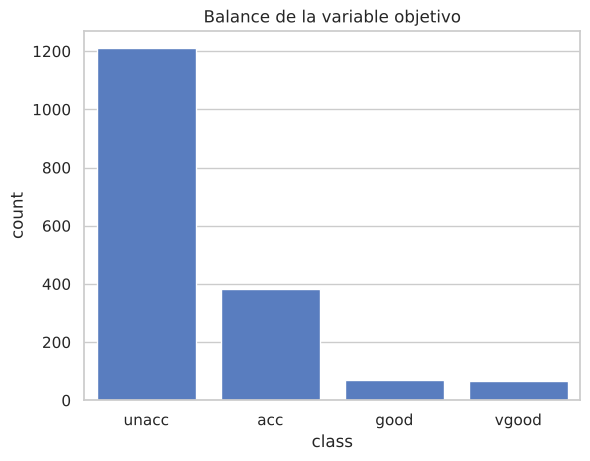

In [5]:
print(df["class"].value_counts())
print()
print((df["class"].value_counts(normalize=True) * 100).round(1))

sns.countplot(data=df, x="class")
plt.title("Balance de la variable objetivo")
plt.show()

El dataset tiene **1728 filas y 7 columnas**. Todas las variables son **categóricas ordinales** (tienen un orden, por
ejemplo `low < med < high < vhigh`), por eso se han convertido a tipo `category` con orden. Aunque `doors` y `persons`
parezcan números, incluyen valores como `5more` o `more`, así que también son categóricas.

Las clases están **muy desbalanceadas**: el 70 % de los coches son `unacc`, el 22 % `acc` y solo un 4 % `good` y otro
4 % `vgood`. Esto habrá que tenerlo en cuenta si luego se entrena un modelo.

## 3. Limpieza de datos

Nulos, duplicados e inconsistencias.

In [6]:
print("Valores nulos:")
print(df.isna().sum())
print()
print("Filas duplicadas:", df.duplicated().sum())

Valores nulos:
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64

Filas duplicadas: 0


In [7]:
# Comprobamos que cada columna solo tiene los valores que indica car.names
for col in df.columns:
    print(col, "->", list(df[col].unique()))

buying -> ['vhigh', 'high', 'med', 'low']
maint -> ['vhigh', 'high', 'med', 'low']
doors -> ['2', '3', '4', '5more']
persons -> ['2', '4', 'more']
lug_boot -> ['small', 'med', 'big']
safety -> ['low', 'med', 'high']
class -> ['unacc', 'acc', 'vgood', 'good']


No hay **valores nulos** ni **filas duplicadas**, y todos los valores coinciden con los que indica `car.names`, así que
no hay inconsistencias. No hace falta limpiar nada.

## 4. Análisis univariable

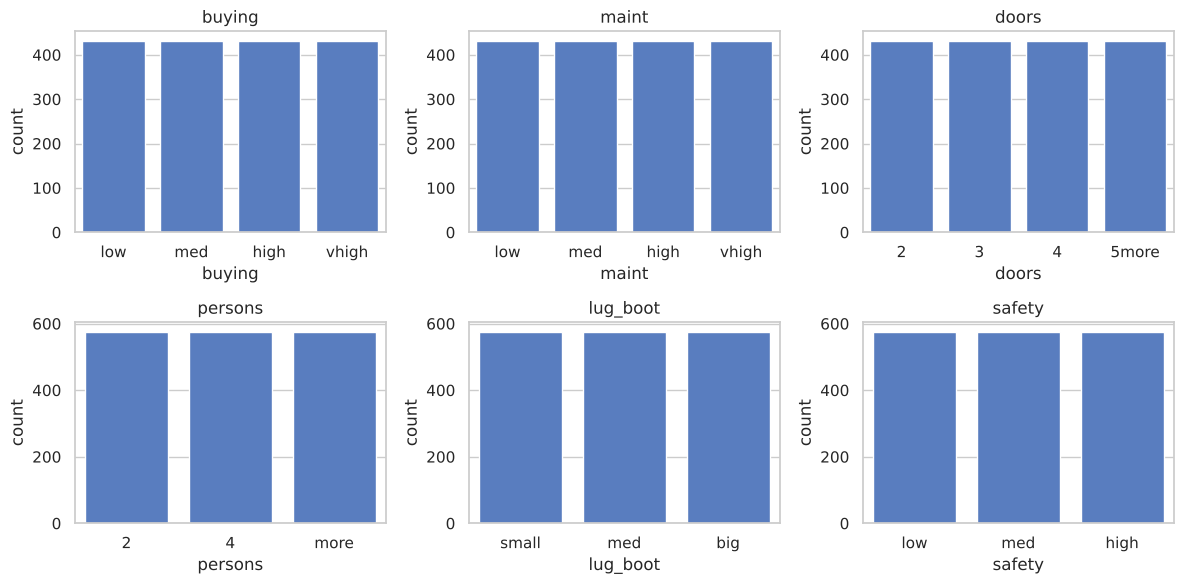

In [8]:
atributos = ["buying", "maint", "doors", "persons", "lug_boot", "safety"]

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.flat, atributos):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Todos los atributos tienen una **distribución uniforme**: cada valor aparece el mismo número de veces (432 veces en las
variables de 4 categorías y 576 en las de 3). Esto se debe a que el dataset incluye todas las combinaciones posibles de
atributos (4·4·4·3·3·3 = 1728), por lo que no hay categorías poco representadas.

## 5. Análisis bivariable / multivariable

Relación de cada característica con la variable objetivo.

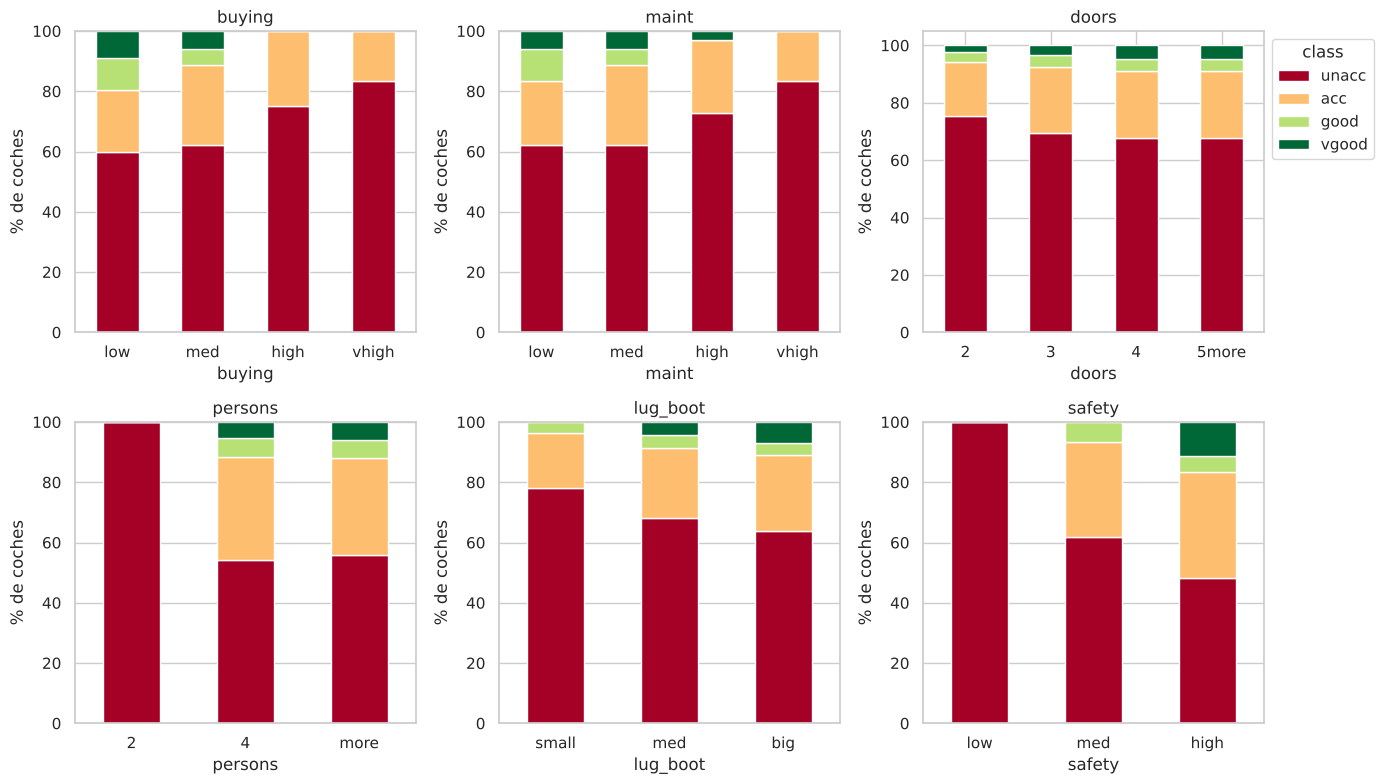

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, atributos):
    tabla = pd.crosstab(df[col], df["class"], normalize="index") * 100
    tabla.plot(kind="bar", stacked=True, ax=ax, legend=False, colormap="RdYlGn")
    ax.set_title(col)
    ax.set_ylabel("% de coches")
    ax.tick_params(axis="x", rotation=0)
axes[0, 2].legend(title="class", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [10]:
# Tablas en % de los atributos más importantes
for col in ["safety", "persons", "buying"]:
    print((pd.crosstab(df[col], df["class"], normalize="index") * 100).round(1))
    print()

class   unacc   acc  good  vgood
safety                          
low     100.0   0.0   0.0    0.0
med      62.0  31.2   6.8    0.0
high     48.1  35.4   5.2   11.3

class    unacc   acc  good  vgood
persons                          
2        100.0   0.0   0.0    0.0
4         54.2  34.4   6.2    5.2
more      55.9  32.3   5.7    6.1

class   unacc   acc  good  vgood
buying                          
low      59.7  20.6  10.6    9.0
med      62.0  26.6   5.3    6.0
high     75.0  25.0   0.0    0.0
vhigh    83.3  16.7   0.0    0.0



In [11]:
# Combinación de personas y seguridad
pd.crosstab([df["persons"], df["safety"]], df["class"])

class           unacc  acc  good  vgood
persons safety                         
2       low       192    0     0      0
        med       192    0     0      0
        high      192    0     0      0
4       low       192    0     0      0
        med        84   90    18      0
        high       36  108    18     30
more    low       192    0     0      0
        med        81   90    21      0
        high       49   96    12     35

- **`safety`** es el atributo más importante: si la seguridad es `low`, el coche es **siempre** `unacc`. Además, `vgood`
  solo aparece con seguridad `high`.
- **`persons`** también es clave: si el coche es de 2 personas, es **siempre** `unacc`.
- **`buying` y `maint`**: cuanto más caros, peor clase. Con precio `high` o `vhigh` ningún coche llega a `good` ni a
  `vgood`.
- **`lug_boot`**: con maletero pequeño (`small`) no hay ningún coche `vgood`.
- **`doors`** apenas cambia la distribución de clases, así que casi no influye.

En la tabla de `persons` × `safety` se ve que con 2 personas o seguridad baja todos los coches son `unacc`. Juntando las
dos condiciones salen 960 coches, que son la mayor parte de los 1210 `unacc`.

## 6. Conclusiones e insights

1. Los datos están **limpios**: no hay nulos, duplicados ni valores raros.
2. La variable objetivo está **desbalanceada** (70 % `unacc`), así que en un modelo no bastaría con mirar la *accuracy*.
3. Los atributos más importantes son la **seguridad** y el **número de personas**: seguridad baja o 2 personas hacen que
   el coche sea siempre inaceptable.
4. El **precio** y el **mantenimiento** también influyen: cuanto más caros, peor valoración.
5. El **número de puertas** prácticamente no influye en la clase.